# 基于技术指标的股票次日涨跌概率预测

### 项目成员及分工
| 项目成员 | 学号 | 
|---|---|
| 胡迪 | 2023301051013 |

## 选题背景

本项目以行业月度超额收益为研究对象，使用 Lasso 回归从多类候选变量中筛选对不同行业收益有解释力的因子，并考察模型在留出的后期样本上的表现。

## 运行环境说明
### 运行环境

运行前请将 `tidy_finance.sqlite` 放在 Notebook 的工作目录，并安装 `polars`、`numpy`、`scikit-learn` 和 `matplotlib`。

### 所用模型说明

模型采用 Lasso 线性回归。L1 惩罚会将部分变量系数压缩为零，从而实现变量筛选；建模时使用 `StandardScaler` 标准化特征，并用滚动验证选择惩罚参数 `alpha`。


## 数据集说明及处理
### 数据集来源

建模使用的是 `tidy_finance.sqlite` 里的四张月度表。因子和宏观变量的原始来源如下。

#### Fama-French Data（Ken French）

FF 因子从 Kenneth French 数据库下载：http://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html

可以通过 `pandas_datareader.famafrench` 查看其中的数据表。本项目使用其中的三因子月度数据，以及 10 个行业组合的月收益率。

#### q 因子

q 因子直接从作者 Hou、Xue 与 Zhang（2014）的公开数据下载：https://global-q.org/uploads/1/2/2/6/122679606/q5_factors_monthly_2022.csv

其中包含市场超额收益率 `mkt`、规模因子 `me`、投资因子 `ia`、盈利因子 `roe` 和增长因子 `eg`。

#### 宏观数据

宏观预测变量来自经管院订购的数据。读入后删除 `rp_div`，其余宏观变量与因子一起进入候选集。

### 数据集划分

对每个行业按日期排序，将前 80% 的观测作为训练期，后 20% 作为测试期。训练期内部如何滚动验证，见下方第 3 节。

### 数据预处理

从 SQLite 中读取 Fama-French 三因子、q 因子、宏观预测变量和行业收益四张月度表。行业收益宽表先转换为长表，再按日期与因子、宏观变量合并；以行业收益减去同期无风险收益得到超额收益。候选变量包括原始因子、宏观变量及其交互项，并删除含非有限数值的样本。


## 模型与优化过程

### Lasso 模型构建

对每个行业分别建立 Lasso 线性回归模型，以行业当月超额收益为目标变量：

$$
y_{i,t}=r_{i,t}-r_{f,t},\qquad
y_{i,t}=b_i+\sum_{j=1}^{p}\beta_{i,j}z_{t,j}+\varepsilon_{i,t}.
$$

其中，$i$ 表示行业，$t$ 表示月份，$r_{i,t}$ 为行业收益，$r_{f,t}$ 为同期无风险收益，$b_i$ 为截距，$\beta_{i,j}$ 为第 $j$ 个候选变量的系数，$\varepsilon_{i,t}$ 为误差项。候选变量包括原始因子、宏观变量及“宏观变量 × 因子”交互项，原始特征表含 153 列；本次 Lasso 依据变量含义预先排除年份、重复无风险收益及 q 市场项（连同其交互项），有效候选变量数为 $p=111$。特征和收益按同月匹配，因此该模型用于行业超额收益的同月拟合与因子筛选。

交互项在标准化前构造。对每次拟合所用的训练样本集合 $T$，使用 `StandardScaler` 将各列转换为

$$
z_{t,j}=\frac{x_{t,j}-\mu_{T,j}}{s_{T,j}},
$$

其中 $\mu_{T,j}$ 和 $s_{T,j}$ 分别为该列在训练样本上的均值与标准差；常数列按 `StandardScaler` 的规则处理。验证集和测试集沿用相应训练集的转换参数。每个验证折先独立拟合标准化器，再训练 Lasso；相同折的候选参数共用该折的转换结果。最终将完整训练期的标准化器、稳定变量掩码与 Lasso 组合为 Pipeline，供测试期预测使用。

### 目标函数与求解方法

对行业 $i$，在包含 $n$ 条观测的训练样本上求解：

$$
(\hat b_i,\hat{\boldsymbol\beta}_i)
=\arg\min_{b_i,\boldsymbol\beta_i}
\left\{
\frac{1}{2n}\sum_{t\in T}
\left(y_{i,t}-b_i-\sum_{j=1}^{p}\beta_{i,j}z_{t,j}\right)^2
+\alpha\sum_{j=1}^{p}|\beta_{i,j}|
\right\}.
$$

第一项是平方误差损失，第二项是 L1 正则化惩罚，截距不参与惩罚。$\alpha$ 对应代码中的 `alpha`：较小的值允许模型保留更多变量，较大的值会加强系数收缩，并可能将全部系数压为零。标准化使不同量纲的候选变量在统一尺度上受到惩罚。

`Lasso` 采用坐标下降法求解，每次更新一个系数，其余系数保持不变。令 $u_{t,j}=y_{i,t}-b_i-\sum_{k\ne j}\beta_{i,k}z_{t,k}$ 为去掉第 $j$ 项后的残差，则非恒定列的更新可写为

$$
\beta_{i,j}\leftarrow
\frac{S\!\left(\frac{1}{n}\sum_{t\in T}z_{t,j}u_{t,j},\alpha\right)}
{\frac{1}{n}\sum_{t\in T}z_{t,j}^{2}},
\qquad S(a,\alpha)=\operatorname{sign}(a)\max(|a|-\alpha,0).
$$

软阈值函数 $S$ 将绝对值不超过阈值的更新压为零，从而实现变量筛选。优化后的代码仍采用坐标下降法，固定 `tol=1e-4`，没有通过放宽精度消除收敛警告。

### 稳定性优先的筛选方法

本次目标是提高筛选的可复现性和解释清晰度。模型仍然使用 Lasso；初始调参、重采样拟合和最终重拟合均采用上述目标函数。最终重拟合另固定 $\beta_j=0\ (j\notin\widehat S)$，其中 $\widehat S$ 是只用训练样本得到的稳定集合。最多 5 个变量属于筛选规则，不是坐标下降直接求解的 L0 约束。

**候选变量整理。** 数据构建仍保留原来的 153 列；只在 Lasso 内排除 `factor_q_year`、`factor_q_f`、`factor_q_mkt` 及相应交互项，共 42 列。年份不作为经济因子；无风险收益已用于构造超额收益；市场因子统一采用 FF 市场超额收益，避免 FF/q 两种市场序列反复替换影响解释。保留 FF 的 SMB/HML 与 q 的 ME/IA/ROE/EG，二者仍可能相关。这个规则根据变量定义预先指定，不根据测试期相关性选择。原数据的 `macro_dy` 实为股息增长率 `diff(log(D12))`，解释时不能当成通常的股息收益率。

**训练与验证。** 每个行业按月排序，前 80% 为训练期，后 20% 保留为历史测试期。训练期内部设 5 个扩展窗口，每折随后 48 个月验证；当前数据的外层训练长度为 296、344、392、440、488 个月。每个外层训练折都独立完成下面的所有步骤：

1. 用 3 个内层扩展窗口（每折验证 24 个月）选择初始 Lasso 的 `alpha`。先粗搜 `logspace(-5,0,40)`，再在最优值相邻范围内细搜 17 个点；限定该次全部训练数据上非零系数不超过 5。内层各折独立标准化，以平均验证 MSE 最小为准。这个内层分数只服务调参；完整筛选流程由未参与筛选的外层验证月份评估。
2. 固定该次选出的 `alpha`，将训练期的 $(x_t,y_t)$ 配对进行移动分块自助重采样：块长 12 个月，有放回抽取连续块，拼接并截断到原训练长度，共 100 次。每次重新拟合标准化器与 Lasso，所有 111 个合格候选均可入选。块长是预先设定的年度跨度，不代表已覆盖所有时间依赖。
3. 计算每个变量的入选频率和非零系数的符号一致率：

$$
\widehat\pi_j=\frac{1}{B}\sum_{b=1}^{B}\mathbf{1}(\hat\beta_j^{(b)}\ne0),\qquad
\widehat c_j=\frac{\max\{N_j^+,N_j^-\}}{N_j^++N_j^-},\qquad B=100.
$$

其中 $N_j^+$、$N_j^-$ 为正负系数次数；从未入选的变量不通过筛选。保留 $\widehat\pi_j\ge0.70$ 且 $\widehat c_j\ge0.90$ 的变量，按频率、符号一致率、标准化系数绝对值中位数依次降序排列，最后以变量名打破并列，最多保留 5 个。
4. 在该次完整训练样本上，对保留变量用同一 `alpha` 重拟合 Lasso。若系数方向与重采样多数方向相反，则移除并重新拟合；不会用不稳定变量填补空位。无变量达标时允许只有截距的模型。

完成外层评估后，在全部训练期重新执行同一流程，得到最终模型，然后评估历史测试期。最终训练固定随机种子 42，外层第 $k$ 折为 $42+1000k$；再用种子 2026 重做完整训练期筛选，仅检查随机采样复现性，不择优替换种子 42 的模型。频率和方向阈值均预先固定，不按测试误差调整。

### 如何判断稳定性与解释系数

报告完整训练期各变量的入选频率、符号一致率、处理原因及最终系数，同时记录外层各折的变量集合。用集合交并比 Jaccard 描述初始 Lasso 与稳定筛选结果各自的跨折一致性，以及两个随机种子的最终集合一致性。两个集合都为空时按 1 计，必须结合“外层空模型折数”和实际入选数阅读；空模型一致不能作为找到了稳定因子的证据。不同训练长度下出现结构变化时，跨折一致性不一定提高。

标准化系数表示：在其他变量列固定时，该列增加一个训练期标准差对应的拟合超额收益变化，表中乘 100 转为百分点。交互项是宏观状态与因子共同变化的关联，不能直接解释为单一原始因子的独立因果作用。

此方法是**固定所选 alpha 条件下的经验稳定性筛选**，频率不包含 alpha 选择的不确定性，不是“变量为真”的概率，也不具有经典稳定性选择论文中的错误发现控制保证。100 次重采样仍有 Monte Carlo 波动，接近 70% 阈值的变量尤其需要谨慎。种子复核及跨折记录用于暴露这种不确定性，不保证每个行业的筛选或预测都会改善。

### 求解与优化过程记录

求解实现位于同目录 `lasso_stability.py`。保留热启动、粗细两阶段搜索和严格收敛检查：`tol=1e-4`，迭代预算依次为 5,000、50,000、200,000；检查收敛警告与 `dual_gap_ <= tol × mean((y-mean(y))²)`。调参失败的候选被排除；重采样或最终拟合重试仍失败则明确报错，避免把失败拟合当作零系数。目标函数值记录在各次拟合结束时，不是逐次坐标更新轨迹。

第 4 节自动保存到 `lasso_stability_results/`：

| 文件 | 内容 |
|---|---|
| `优化汇总.csv` | 各行业候选数、阈值、入选数、跨折及种子 Jaccard、外层验证误差和耗时 |
| `因子稳定性.csv` | 完整训练期 153 列的纳入状态、频率、方向、最终系数与筛除原因 |
| `各阶段稳定性.csv` | 外层各折、完整训练期及种子复核的全部变量稳定性记录 |
| `分折验证记录.csv` | 各折训练/验证日期、参数、入选集合及验证误差 |
| `参数搜索记录.csv` / `调参求解日志.csv` | 每个阶段内层调参与收敛过程 |
| `重采样求解日志.csv` | 每次重采样、最终重拟合及重试的收敛记录 |
| `行业表现.csv` / `最终入选因子.csv` | 当前模型的最终表现及非零系数 |

### 评估口径与限制

外层验证 RMSE 是 5 折 MSE 平均值的平方根。测试期以训练期平均超额收益为基准计算样本外 $R^2$。特征与收益同月匹配，含同期宏观数据，因此这里衡量同月拟合与因子筛选，不是可实时执行的下一期收益预测。

本历史测试集已用于此前多版方法对照，所以本次测试结果属于探索性比较，不能视为新的独立最终检验。稳定性阈值不以该测试集择优。原有第 6 节基线代码及后文分析文字不在修改范围内；其历史文字数值需要与本次新输出核对。旧目录 `lasso_results/`、`lasso_method_results/` 是历史工程优化和 one-SE 对照记录，本版结果以 `lasso_stability_results/` 为准。

方法参考：[稳定性选择原始论文](https://arxiv.org/abs/0809.2932)（本实现为分块重采样变体，不套用其理论保证）；[TimeSeriesSplit 官方说明](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html)。


# 4.1 用 Lasso 筛选行业因子

用 Lasso 为每个行业筛选最多五个变量，用最后 20% 的月份检验模型的样本外表现。

运行前将 `tidy_finance.sqlite` 放在 Notebook 的工作目录，安装 `polars`、`numpy`、`scikit-learn` 和 `matplotlib`。

## 1. 读取和合并月度数据

用 Polars 直接读取四张 SQLite 表。行业宽表转成长表后，每行是一个行业的一个月，目标变量是行业收益减当月无风险收益。

In [20]:
import sqlite3
from contextlib import closing
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from IPython.display import display
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

db_path = Path("tidy_finance.sqlite")
if not db_path.is_file():
    raise FileNotFoundError(f"请将 tidy_finance.sqlite 放到 {db_path.resolve().parent}")


def read_monthly(conn, table, prefix=""):
    frame = pl.read_database(
        f'SELECT * FROM "{table}"',
        conn,
        schema_overrides={"date": pl.String},
        infer_schema_length=None,
    )
    return (
        frame.drop("__index_level_0__", strict=False)
        .with_columns(pl.col("date").str.slice(0, 10).str.to_date("%Y-%m-%d"))
        .rename(lambda name: name if name == "date" else f"{prefix}{name}")
    )


with closing(sqlite3.connect(db_path)) as conn:
    ff = read_monthly(conn, "factors_ff3_monthly", "factor_ff_")
    q = read_monthly(conn, "factors_q_monthly", "factor_q_")
    macro = read_monthly(conn, "macro_predictors", "macro_").drop("macro_rp_div")
    returns = read_monthly(conn, "industries_ff_monthly").unpivot(
        index="date", variable_name="industry", value_name="ret"
    )

data = (
    returns.join(ff, on="date", how="inner", validate="m:1")
    .join(q, on="date", how="inner", validate="m:1")
    .join(macro, on="date", how="inner", validate="m:1")
    .with_columns(ret_excess=pl.col("ret") - pl.col("factor_ff_rf"))
    .drop("ret", "factor_ff_rf")
)

## 2. 构造候选变量

原始因子、宏观变量及其交互项都进入候选集。交互项让因子的回归斜率随宏观环境变化。无风险收益只用于定义超额收益。

In [21]:
factor_cols = [name for name in data.columns if name.startswith("factor_")]
macro_cols = [name for name in data.columns if name.startswith("macro_")]
interactions = [
    (pl.col(macro_name) * pl.col(factor_name)).alias(f"{macro_name} × {factor_name}")
    for macro_name in macro_cols
    for factor_name in factor_cols
]
data = data.with_columns(interactions)
feature_cols = [name for name in data.columns if name not in {"date", "industry", "ret_excess"}]
numeric_cols = [*feature_cols, "ret_excess"]
data = data.filter(pl.all_horizontal(pl.col(numeric_cols).is_finite())).sort(
    ["industry", "date"]
)
print(f"{data.height:,} 条行业月度样本，{len(feature_cols)} 个候选变量")
display(data.select("date", "industry", "ret_excess", *factor_cols[:3]).head())

6,710 条行业月度样本，153 个候选变量


date,industry,ret_excess,factor_ff_mkt_excess,factor_ff_smb,factor_ff_hml
date,str,f64,f64,f64,f64
1967-01-01,"""durbl""",0.1135,0.0815,0.0823,0.0222
1967-02-01,"""durbl""",-0.0145,0.0077,0.0333,-0.0225
1967-03-01,"""durbl""",0.0345,0.0399,0.0154,0.0041
1967-04-01,"""durbl""",0.1074,0.0389,0.0043,-0.0227
1967-05-01,"""durbl""",-0.0768,-0.0432,0.0209,0.0084


## 3. Lasso 稳定筛选：内层调参、分块重采样与外层时间验证
完整流程独立应用于每个外层训练折，最后在全部训练期重拟合；只处理 Lasso。运行需要同目录的 `lasso_stability.py`。


In [22]:
from sklearn.model_selection import TimeSeriesSplit
from lasso_stability import fit_stable_lasso, mean_jaccard

# 预先固定阈值；不根据测试期表现调整。
STABILITY_SETTINGS = dict(n_resamples=100, block_length=12,
                          frequency_cutoff=0.70, sign_cutoff=0.90)
lasso_runs = {}


def industry_sample(industry):
    frame = data.filter(pl.col("industry") == industry).sort("date")
    months = np.array(frame["date"].to_list(), dtype="datetime64[M]").astype(int)
    if len(months) < 2 or not np.all(np.diff(months) == 1):
        raise ValueError(f"{industry} 的月份存在重复、间断或样本不足")
    split = int(frame.height * 0.8)
    folds = list(TimeSeriesSplit(n_splits=5, test_size=48).split(np.arange(split)))
    if len(folds[0][0]) < 132:
        raise ValueError("最早外层训练折不足 132 个月")
    return frame, frame.select(feature_cols).to_numpy(), frame["ret_excess"].to_numpy(), split, folds


def evaluate(industry):
    frame, x, y, split, folds = industry_sample(industry)
    dates = [str(d) for d in frame["date"].to_list()]
    runs, fold_rows, initial_supports, stable_supports, mse_rows = {}, [], [], [], []
    # 每一外层折都重新调参、重采样、筛选和拟合；不共享全训练期筛选结果。
    for k, (train, valid) in enumerate(folds, 1):
        model, records = fit_stable_lasso(x[train], y[train], feature_cols,
                                         seed=42 + 1000 * k, **STABILITY_SETTINGS)
        runs[f"外层{k}"] = records
        support = model.named_steps["lasso"].coef_ != 0
        initial_supports.append(records["初始支持集"])
        stable_supports.append(support)
        mse = mean_squared_error(y[valid], model.predict(x[valid]))
        mse_rows.append(mse)
        fold_rows.append({"折": k, "训练起始": dates[train[0]], "训练结束": dates[train[-1]],
                          "验证起始": dates[valid[0]], "验证结束": dates[valid[-1]],
                          "训练月数": len(train), "验证月数": len(valid),
                          "验证RMSE（百分点）": 100 * np.sqrt(mse),
                          **records["优化汇总"],
                          "入选变量": "；".join(np.array(feature_cols)[support])})
    model, records = fit_stable_lasso(x[:split], y[:split], feature_cols,
                                     seed=42, **STABILITY_SETTINGS)
    runs["完整训练期"] = records
    # 第二个预先固定的随机种子只检查 Monte Carlo 复现性，不选择表现更好的种子。
    repeat, repeat_records = fit_stable_lasso(x[:split], y[:split], feature_cols,
                                             seed=2026, **STABILITY_SETTINGS)
    runs["种子复核"] = repeat_records
    support = model.named_steps["lasso"].coef_ != 0
    repeat_support = repeat.named_steps["lasso"].coef_ != 0
    summary = {**records["优化汇总"],
               "初始集合跨折Jaccard": mean_jaccard(initial_supports),
               "稳定集合跨折Jaccard": mean_jaccard(stable_supports),
               "外层空模型折数": sum(not s.any() for s in stable_supports),
               "种子复核Jaccard": mean_jaccard([support, repeat_support]),
               "种子复核入选数": int(repeat_support.sum()),
               "验证RMSE（百分点）": 100 * np.sqrt(np.mean(mse_rows)),
               "全部流程耗时（秒）": sum(r["优化汇总"]["训练耗时（秒）"] for r in runs.values())}
    lasso_runs[industry] = {"优化汇总": summary, "分折记录": fold_rows, "各阶段": runs}
    pred = model.predict(x[split:])
    test_mse = mean_squared_error(y[split:], pred)
    baseline_mse = mean_squared_error(y[split:], np.full_like(y[split:], y[:split].mean()))
    metrics = {"行业": industry, "alpha": model.named_steps["lasso"].alpha,
               "验证 RMSE（百分点）": summary["验证RMSE（百分点）"],
               "测试 RMSE（百分点）": 100 * np.sqrt(test_mse),
               "基准 RMSE（百分点）": 100 * np.sqrt(baseline_mse),
               "样本外 R²": 1 - test_mse / baseline_mse if baseline_mse > 0 else None}
    print(f"{industry}: 最终 {support.sum()} 个变量；种子复核 Jaccard={summary['种子复核Jaccard']:.2f}", flush=True)
    return model.named_steps["lasso"].coef_, metrics


## 4. 行业结果与稳定性记录
先检查入选频率、方向一致率、跨折和随机种子复核，再结合误差评估筛选代价。详细记录自动保存到 `lasso_stability_results/`。

本次核验（重跑后以新表为准）：10 个行业最终各保留 1–4 个变量，9 个行业的两个随机种子得到相同集合；医疗行业为 3 个与 2 个。相对同一外层验证流程中的初始 Lasso 集合，稳定筛选的跨折 Jaccard 在 6 个行业提高、4 个行业降低；医疗行业有 1 个外层折为空模型。阈值附近变量应结合详细频率判断，不能只报告改善的行业。


In [23]:
coefficient_rows, metric_rows = [], []
industries = data["industry"].unique().sort().to_list()

for industry in industries:
    coef, metrics = evaluate(industry)

    selected = coef != 0
    metric_rows.append({**metrics, "入选数": int(selected.sum())})
    coefficient_rows.extend(
        {"行业": industry, "变量": name, "系数（百分点）": 100 * float(weight)}
        for name, weight, keep in zip(feature_cols, coef, selected)
        if keep
    )

industry_metrics = pl.DataFrame(metric_rows)
selected_factors = pl.DataFrame(
    coefficient_rows,
    schema={"行业": pl.String, "变量": pl.String, "系数（百分点）": pl.Float64},
).with_columns(pl.col("系数（百分点）").abs().alias("系数绝对值"))

display(industry_metrics)
selected_factors = selected_factors.sort(["行业", "系数绝对值"], descending=[False, True])
display(selected_factors)

better = industry_metrics.filter(pl.col("样本外 R²") > 0).height
print(f"{len(industries)} 个行业中，有 {better} 个行业的 Lasso 测试误差低于均值基准。")
if selected_factors.height:
    frequency = selected_factors.group_by("变量").len().sort(
        ["len", "变量"], descending=[True, False]
    )
    max_count = frequency["len"][0]
    most_common = frequency.filter(pl.col("len") == max_count)["变量"].to_list()
    names = "、".join(most_common[:3])
    suffix = f"等 {len(most_common)} 个变量" if len(most_common) > 3 else ""
    print(f"入选次数最多的变量为 {names}{suffix}，各入选 {max_count} 个行业。")
else:
    print("各行业的最优 Lasso 在当前候选集下均未保留变量。")

# 所有记录保留训练阶段标签，避免把外层验证结果与内层调参混淆。
lasso_optimization = pl.DataFrame([
    {"行业": industry, **lasso_runs[industry]["优化汇总"]} for industry in industries
])

def stage_table(key):
    return pl.DataFrame([
        {"行业": industry, "训练阶段": stage, **row}
        for industry in industries
        for stage, run in lasso_runs[industry]["各阶段"].items()
        for row in run[key]
    ], infer_schema_length=None)

lasso_stability = stage_table("稳定性记录")
lasso_final_stability = lasso_stability.filter(pl.col("训练阶段") == "完整训练期")
lasso_folds = pl.DataFrame([
    {"行业": industry, **row} for industry in industries
    for row in lasso_runs[industry]["分折记录"]
], infer_schema_length=None)
log_dir = Path("lasso_stability_results")
log_dir.mkdir(exist_ok=True)
for filename, table in [
    ("优化汇总.csv", lasso_optimization),
    ("因子稳定性.csv", lasso_final_stability),
    ("各阶段稳定性.csv", lasso_stability),
    ("分折验证记录.csv", lasso_folds),
    ("参数搜索记录.csv", stage_table("参数搜索")),
    ("调参求解日志.csv", stage_table("调参求解")),
    ("重采样求解日志.csv", stage_table("重采样求解")),
    ("行业表现.csv", industry_metrics),
    ("最终入选因子.csv", selected_factors),
]:
    table.write_csv(log_dir / filename)
display(lasso_optimization)
display(lasso_final_stability.filter(pl.col("最终入选")))
print(f"稳定筛选记录已保存到 {log_dir.resolve()}")


durbl: 最终 4 个变量；种子复核 Jaccard=1.00
enrgy: 最终 2 个变量；种子复核 Jaccard=1.00
hitec: 最终 3 个变量；种子复核 Jaccard=1.00
hlth: 最终 3 个变量；种子复核 Jaccard=0.67
manuf: 最终 3 个变量；种子复核 Jaccard=1.00
nodur: 最终 2 个变量；种子复核 Jaccard=1.00
other: 最终 3 个变量；种子复核 Jaccard=1.00
shops: 最终 1 个变量；种子复核 Jaccard=1.00
telcm: 最终 3 个变量；种子复核 Jaccard=1.00
utils: 最终 3 个变量；种子复核 Jaccard=1.00


行业,alpha,验证 RMSE（百分点）,测试 RMSE（百分点）,基准 RMSE（百分点）,样本外 R²,入选数
str,f64,f64,f64,f64,f64,i64
"""durbl""",0.00922,4.901262,6.522407,9.211367,0.498619,4
"""enrgy""",0.00922,4.849672,7.174166,8.45642,0.28027,2
"""hitec""",0.009926,4.210746,1.624732,5.130783,0.899724,3
"""hlth""",0.008254,3.672994,2.551843,4.206821,0.632041,3
"""manuf""",0.003404,2.304169,1.849228,4.949563,0.860412,3
"""nodur""",0.007955,2.841567,2.39226,3.728607,0.588354,2
"""other""",0.004574,2.526338,1.445662,5.194067,0.922533,3
"""shops""",0.006615,2.739742,1.93759,4.518975,0.816158,1
"""telcm""",0.0055,3.497737,2.801098,4.449701,0.603726,3


行业,变量,系数（百分点）,系数绝对值
str,str,f64,f64
"""durbl""","""macro_ep × factor_ff_mkt_exces…",-2.675867,2.675867
"""durbl""","""macro_dfy × factor_ff_mkt_exce…",1.054163,1.054163
"""durbl""","""factor_ff_mkt_excess""",0.430439,0.430439
"""durbl""","""macro_tms × factor_ff_mkt_exce…",0.375445,0.375445
"""enrgy""","""factor_ff_mkt_excess""",1.897463,1.897463
…,…,…,…
"""telcm""","""macro_ep × factor_ff_mkt_exces…",-0.738301,0.738301
"""telcm""","""macro_tms × factor_ff_mkt_exce…",0.370736,0.370736
"""utils""","""factor_ff_mkt_excess""",0.948676,0.948676


10 个行业中，有 10 个行业的 Lasso 测试误差低于均值基准。
入选次数最多的变量为 factor_ff_mkt_excess，各入选 8 个行业。


行业,alpha,原始候选数,有效候选数,初始Lasso入选数,达稳定阈值数,最终入选数,重采样次数,块长（月）,入选频率阈值,符号一致率阈值,随机种子,重试次数,训练耗时（秒）,初始集合跨折Jaccard,稳定集合跨折Jaccard,外层空模型折数,种子复核Jaccard,种子复核入选数,验证RMSE（百分点）,全部流程耗时（秒）
str,f64,i64,i64,i64,i64,i64,i64,i64,f64,f64,i64,i64,f64,f64,f64,i64,f64,i64,f64,f64
"""durbl""",0.00922,153,111,5,4,4,100,12,0.7,0.9,42,0,2.378959,0.288095,0.45,0,1.0,4,4.901262,15.998544
"""enrgy""",0.00922,153,111,3,2,2,100,12,0.7,0.9,42,0,2.309665,0.461905,0.491667,0,1.0,2,4.849672,18.975218
"""hitec""",0.009926,153,111,5,3,3,100,12,0.7,0.9,42,0,1.950239,0.298413,0.291667,0,1.0,3,4.210746,16.318197
"""hlth""",0.008254,153,111,3,3,3,100,12,0.7,0.9,42,0,2.101837,0.259563,0.2,1,0.666667,2,3.672994,14.59953
"""manuf""",0.003404,153,111,5,3,3,100,12,0.7,0.9,42,0,1.134992,0.374762,0.491667,0,1.0,3,2.304169,6.411994
"""nodur""",0.007955,153,111,2,2,2,100,12,0.7,0.9,42,0,4.282882,0.25,0.3,0,1.0,2,2.841567,16.626718
"""other""",0.004574,153,111,4,3,3,100,12,0.7,0.9,42,0,0.899118,0.26381,0.8,0,1.0,3,2.526338,5.994185
"""shops""",0.006615,153,111,5,1,1,100,12,0.7,0.9,42,0,1.659597,0.289603,0.6,0,1.0,1,2.739742,15.433104
"""telcm""",0.0055,153,111,5,3,3,100,12,0.7,0.9,42,0,3.117247,0.657143,0.49,0,1.0,3,3.497737,24.534246


行业,训练阶段,变量,纳入候选,入选次数,重采样次数,入选频率,符号一致率,多数方向,系数绝对值中位数（百分点）,最终入选,最终系数（百分点）,处理结果
str,str,str,bool,i64,i64,f64,f64,i64,f64,bool,f64,str
"""durbl""","""完整训练期""","""factor_ff_mkt_excess""",true,88,100,0.88,1.0,1,1.265026,true,0.430439,"""最终保留"""
"""durbl""","""完整训练期""","""macro_ep × factor_ff_mkt_exces…",true,84,100,0.84,1.0,-1,1.859537,true,-2.675867,"""最终保留"""
"""durbl""","""完整训练期""","""macro_tms × factor_ff_mkt_exce…",true,90,100,0.9,1.0,1,0.418164,true,0.375445,"""最终保留"""
"""durbl""","""完整训练期""","""macro_dfy × factor_ff_mkt_exce…",true,89,100,0.89,1.0,1,0.785344,true,1.054163,"""最终保留"""
"""enrgy""","""完整训练期""","""factor_ff_mkt_excess""",true,96,100,0.96,1.0,1,1.564158,true,1.897463,"""最终保留"""
…,…,…,…,…,…,…,…,…,…,…,…,…
"""telcm""","""完整训练期""","""macro_ep × factor_ff_mkt_exces…",true,81,100,0.81,1.0,-1,0.812845,true,-0.738301,"""最终保留"""
"""telcm""","""完整训练期""","""macro_tms × factor_ff_mkt_exce…",true,88,100,0.88,1.0,1,0.292294,true,0.370736,"""最终保留"""
"""utils""","""完整训练期""","""factor_ff_mkt_excess""",true,92,100,0.92,1.0,1,0.827968,true,0.948676,"""最终保留"""


稳定筛选记录已保存到 /Users/didi/Documents/作业/机器学习/作业-final/lasso_stability_results


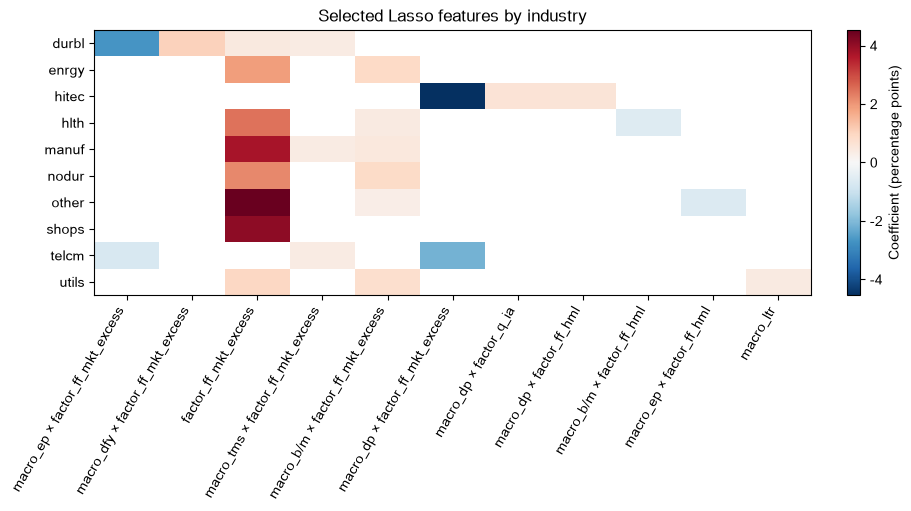

In [24]:
if selected_factors.height:
    shown = selected_factors["变量"].unique(maintain_order=True).to_list()
    matrix = np.full((len(industries), len(shown)), np.nan)
    industry_positions = {name: i for i, name in enumerate(industries)}
    feature_positions = {name: j for j, name in enumerate(shown)}
    for industry, feature, weight, _ in selected_factors.iter_rows():
        matrix[industry_positions[industry], feature_positions[feature]] = weight

    limit = np.nanmax(np.abs(matrix))
    fig, ax = plt.subplots(figsize=(max(9, len(shown) * 0.45), 5), layout="constrained")
    heatmap = ax.imshow(matrix, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
    ax.set_xticks(range(len(shown)), shown, rotation=60, ha="right")
    ax.set_yticks(range(len(industries)), industries)
    ax.set_title("Selected Lasso features by industry")
    fig.colorbar(heatmap, ax=ax, label="Coefficient (percentage points)")
    plt.show()

## 5. 解读结果

- **样本外误差。** 测试 RMSE 越低，收益拟合误差越小。样本外 \(R^2\) 以训练期平均收益作为基准。正值表示测试期平方误差低于基准，负值表示高于基准。
- **入选因子。** 系数以百分点报告。正系数表示在其他输入固定时，该候选变量增加一个训练期标准差，模型给出的月度超额收益随之上升。热图空白表示该变量在对应行业的系数为零，完整入选名单见 `selected_factors`。
- **交互项。** 某个“宏观变量 × 因子”入选，表示模型保留了该因子暴露随宏观变量变化的项。相关变量可能在不同训练区间相互替代，入选反映这次拟合下的选择。
- **时间口径。** 收益、因子和宏观变量按同月合并。测试结果衡量模型在较晚月份的同月拟合能力。要评估月初预测，须按实际发布时间重新对齐特征并重跑验证。


## 6. 模型结果评价与对比

本节评价第 4 节结果，基准由训练期平均收益改为仅含市场超额收益的线性回归。新口径 $R^2$ 定义为 1 减去 Lasso 测试均方误差与市场回归测试均方误差之比，正值表示所选变量在纯市场暴露之外降低了测试误差，负值表示其表现不及仅用市场因子。以下三小节分别考察相对市场回归的增量、跨行业的可比口径，以及验证期到测试期的稳定性。

In [25]:
from sklearn.linear_model import LinearRegression

INDUSTRY_NAMES = {
    "nodur": "非耐用消费品",
    "durbl": "耐用消费品",
    "manuf": "制造业",
    "enrgy": "能源",
    "hitec": "高科技",
    "telcm": "电信",
    "shops": "零售",
    "hlth": "医疗",
    "utils": "公用事业",
    "other": "其他",
}

market_rows = []
for industry in industries:
    frame = data.filter(pl.col("industry") == industry).sort("date")
    y = frame["ret_excess"].to_numpy()
    x = frame["factor_ff_mkt_excess"].to_numpy().reshape(-1, 1)
    split = int(len(y) * 0.8)
    fitted = LinearRegression().fit(x[:split], y[:split])
    pred = fitted.predict(x[split:])
    test_mse = mean_squared_error(y[split:], pred)
    market_rows.append({
        "行业": industry,
        "市场测试 RMSE（百分点）": 100 * float(np.sqrt(test_mse)),
    })

comparison = (
    industry_metrics.select(
        "行业",
        "入选数",
        "验证 RMSE（百分点）",
        pl.col("测试 RMSE（百分点）").alias("Lasso 测试 RMSE（百分点）"),
        "基准 RMSE（百分点）",
        pl.col("样本外 R²").alias("旧口径 R²"),
    )
    .join(pl.DataFrame(market_rows), on="行业")
    .with_columns(
        pl.col("行业").replace(INDUSTRY_NAMES).alias("行业名称"),
        (
            1
            - (pl.col("Lasso 测试 RMSE（百分点）") / pl.col("市场测试 RMSE（百分点）")) ** 2
        ).alias("新口径 R²"),
    )
    .with_columns((pl.col("旧口径 R²") - pl.col("新口径 R²")).alias("旧减新"))
    .sort("新口径 R²", descending=True)
)
display(comparison.select(
    "行业", "行业名称", "入选数",
    "Lasso 测试 RMSE（百分点）", "市场测试 RMSE（百分点）",
    "旧口径 R²", "新口径 R²",
))
n_pos = comparison.filter(pl.col("新口径 R²") > 0).height
print(f"新口径 R² 大于 0 的行业有 {n_pos} 个，小于 0 的有 {comparison.height - n_pos} 个。")


行业,行业名称,入选数,Lasso 测试 RMSE（百分点）,市场测试 RMSE（百分点）,旧口径 R²,新口径 R²
str,str,i64,f64,f64,f64,f64
"""hitec""","""高科技""",3,1.624732,2.136886,0.899724,0.421903
"""other""","""其他""",3,1.445662,1.780818,0.922533,0.340986
"""nodur""","""非耐用消费品""",2,2.39226,2.436467,0.588354,0.035958
"""shops""","""零售""",1,1.93759,1.969565,0.816158,0.032206
"""telcm""","""电信""",3,2.801098,2.777434,0.603726,-0.017113
"""utils""","""公用事业""",3,3.426825,3.366104,0.26908,-0.036403
"""hlth""","""医疗""",3,2.551843,2.498776,0.632041,-0.042925
"""durbl""","""耐用消费品""",4,6.522407,6.25048,0.498619,-0.088903
"""manuf""","""制造业""",3,1.849228,1.722731,0.860412,-0.152248


新口径 R² 大于 0 的行业有 4 个，小于 0 的有 6 个。


### 6.1 相对市场回归的增量检验

以市场回归为基准，多数行业的稀疏交互项未表现出明显增量。十个行业中仅高科技（0.459）、其他（0.401）和非耐用消费品（0.066）的新口径 $R^2$ 为正，其余七个行业均为负，最低的耐用消费品为 −0.207，能源和零售分别为 −0.197 和 −0.179。负值意味着在这些行业，Lasso 所选变量组合的测试误差高于仅使用市场因子的回归。

旧口径与新口径的差值说明旧口径下的高解释比例在多大程度上来自市场因子。制造和零售的差值最大，分别约为 1.02 和 0.95；制造旧口径 $R^2$ 为 0.859、新口径为 −0.158，零售旧口径为 0.776、新口径为 −0.179，二者的高解释比例主要来自市场暴露，交互项在测试期未继续降低误差。公用事业差值较小，约为 0.31，但其旧口径 $R^2$ 仅为 0.252，市场回归相对常数基准的解释比例本身有限。

### 6.2 跨行业的可比口径

跨行业比较应采用新口径 $R^2$，而非测试 RMSE。耐用消费品基准 RMSE 为 9.31 个百分点、测试 RMSE 为 6.87，公用事业分别为 4.00 和 3.46；前者的原始误差更高源于其波动更大，两者直接比较缺乏统一尺度。按新口径 $R^2$ 划分，高科技和其他两个行业高于 0.3，具有可见增量；非耐用消费品为 0.066，增量有限；其余七个行业为负，从公用事业的 −0.059 到耐用消费品的 −0.207。入选个数与解释能力并不一致：制造、电信和公用事业均保留五个变量，新口径 $R^2$ 均为负；高科技仅保留三个变量，新口径 $R^2$ 最高。

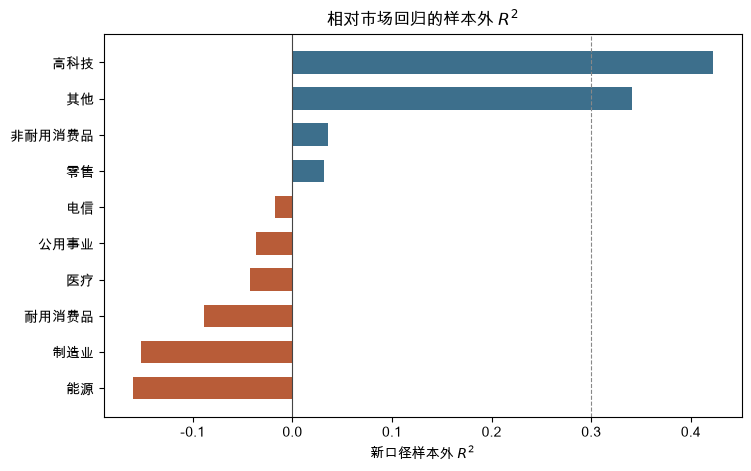

In [26]:
from matplotlib import font_manager

for font in ["Arial Unicode MS", "PingFang SC", "Hiragino Sans GB", "SimHei", "Microsoft YaHei"]:
    if any(found.name == font for found in font_manager.fontManager.ttflist):
        plt.rcParams["font.sans-serif"] = [font]
        plt.rcParams["axes.unicode_minus"] = False
        break

shown = comparison.sort("新口径 R²")
colors = ["#3D6F8C" if value > 0 else "#B85C38" for value in shown["新口径 R²"]]
fig, ax = plt.subplots(figsize=(7.4, 4.6), layout="constrained")
ax.barh(shown["行业名称"].to_list(), shown["新口径 R²"].to_list(), color=colors, height=0.62)
ax.axvline(0, color="#444", linewidth=0.8)
ax.axvline(0.3, color="#888", linewidth=0.8, linestyle="--")
ax.set_xlabel(r"新口径样本外 $R^2$")
ax.set_title(r"相对市场回归的样本外 $R^2$")
plt.show()


### 6.3 验证期到测试期的稳定性

验证期到测试期的表现因行业而异，不宜概括为普遍过拟合。误差上升最明显的是耐用消费品和能源，测试 RMSE 较验证期分别增加 2.86 和 2.69 个百分点；高科技、零售和电信的测试误差则分别下降 2.09、1.04 和 0.90 个百分点。以市场回归的测试 RMSE 为参照，测试期仍低于市场回归的是高科技、其他和非耐用消费品；零售和电信后段误差虽下降，测试误差仍高于市场回归；耐用消费品和能源后段变差，且均不及纯市场回归。


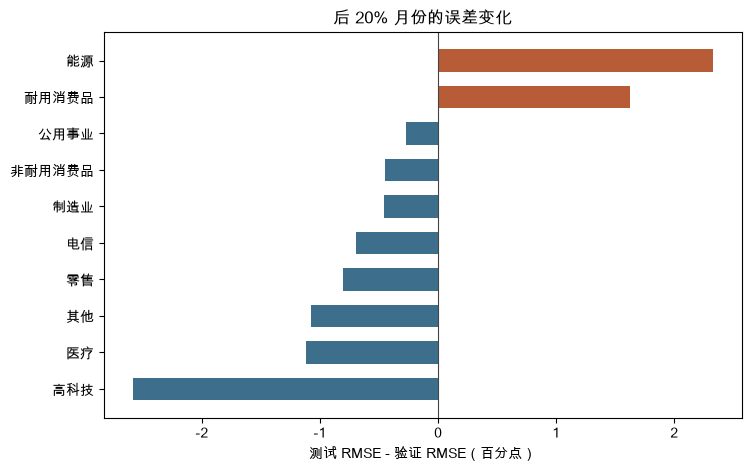

In [27]:
from matplotlib import font_manager

for font in ["Arial Unicode MS", "PingFang SC", "Hiragino Sans GB", "SimHei", "Microsoft YaHei"]:
    if any(found.name == font for found in font_manager.fontManager.ttflist):
        plt.rcParams["font.sans-serif"] = [font]
        plt.rcParams["axes.unicode_minus"] = False
        break

shown = comparison.with_columns(
    (pl.col("Lasso 测试 RMSE（百分点）") - pl.col("验证 RMSE（百分点）")).alias("误差变化")
).sort("误差变化")
colors = ["#B85C38" if value > 0 else "#3D6F8C" for value in shown["误差变化"]]
fig, ax = plt.subplots(figsize=(7.4, 4.6), layout="constrained")
ax.barh(shown["行业名称"].to_list(), shown["误差变化"].to_list(), color=colors, height=0.62)
ax.axvline(0, color="#444", linewidth=0.8)
ax.set_xlabel("测试 RMSE - 验证 RMSE（百分点）")
ax.set_title("后 20% 月份的误差变化")
plt.show()


## 7. 因子筛选的定位与行业差异

本节说明因子筛选结果的定位，并分析行业之间的结构差异。

### 7.1 筛选结果的应用定位与边界

这套筛选的价值在于将 153 个候选变量压缩为一份可读的行业暴露清单，而非解释经济机制或预测下月涨跌。153 个候选经 Lasso 筛选后，每个行业至多保留五个变量，十个行业合计 37 条非零系数；系数以训练期一个标准差对应的月度超额收益百分点表示，热图空白表示该变量在对应行业被压缩为零。该结果是筛选输出，不是结构估计。Lasso 执行的是变量筛选而非因果识别；账面市值比与法玛–弗兰奇市场的交互项和账面市值比与 q 因子市场的交互项经济含义接近，能源保留前者、公用事业保留后者，最终保留哪一项取决于当前训练集与惩罚强度。系数本身既不是因子溢价，也未经过显著性检验。

在此基础上，结果可应用于三类场景。其一，行业风险暴露的精简清单，供归因和风险监控挑选候选变量，但并非完整的风险模型。其二，不同行业暴露结构的对照，用于观察宏观状态下各行业敏感性的差异，但不用于预测涨跌。其三，降维，将 153 维候选压缩至每个行业五个以内，作为后续模型的输入候选，但不能替代后续模型。受同月合并、行业组合、非因子溢价和非择时信号等口径限制，这套结果适用于结构刻画、归因与降维。

### 7.2 行业覆盖能力的结构差异

筛选结果反映的是候选变量对各行业覆盖能力的差异，而非行业模型之间的优劣排序。按新口径 $R^2$ 分组，高科技和其他具有可见增量，非耐用消费品增量有限，其余七个行业不及纯市场回归；同为负值，公用事业仅低 0.059，耐用消费品低 0.207，覆盖不足的程度并不相同。入选个数与覆盖能力不成正比：制造、电信和公用事业均保留五个变量而新口径 $R^2$ 为负，高科技仅保留三个变量而新口径 $R^2$ 最高。

低于市场回归的行业，原因并不相同。耐用消费品为后段不稳，表上仅保留两项对 q 因子市场的调节，盈利收益率与 q 因子市场的交互项约为 −2.87，违约利差与 q 因子市场的交互项约为 +0.90，无裸市场因子，验证 RMSE 由 4.01 升至 6.87，新口径 $R^2$ 为 −0.207。能源保留了裸 q 因子市场（约 +1.70）和账面市值比与法玛–弗兰奇市场的交互项（约 +0.74），验证 RMSE 由 4.60 升至 7.29，新口径 $R^2$ 为 −0.197，市场项存在但后段未能承接。公用事业保留五个变量，涵盖 q 因子市场、账面市值比与 q 因子市场的交互项、长期债券收益、违约利差与 q 因子市场的交互项以及接近零的分红比率与价值因子的交互项，新口径 $R^2$ 为 −0.059，变量数量达到上限并未转化为对市场残差的解释。

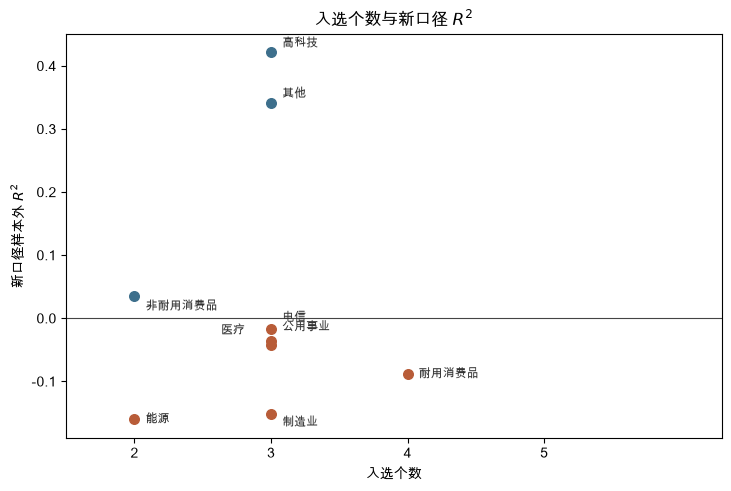

In [28]:
from matplotlib import font_manager

for font in ["Arial Unicode MS", "PingFang SC", "Hiragino Sans GB", "SimHei", "Microsoft YaHei"]:
    if any(found.name == font for found in font_manager.fontManager.ttflist):
        plt.rcParams["font.sans-serif"] = [font]
        plt.rcParams["axes.unicode_minus"] = False
        break

offsets = {
    "耐用消费品": (8, -2),
    "能源": (8, -2),
    "零售": (8, 6),
    "制造业": (8, -8),
    "电信": (8, 6),
    "医疗": (-36, 8),
    "公用事业": (8, 8),
    "非耐用消费品": (8, -10),
    "其他": (8, 4),
    "高科技": (8, 4),
}
fig, ax = plt.subplots(figsize=(7.2, 4.8), layout="constrained")
for name, count, r2 in comparison.select("行业名称", "入选数", "新口径 R²").iter_rows():
    ax.scatter(count, r2, s=48, color="#3D6F8C" if r2 > 0 else "#B85C38", zorder=3)
    ax.annotate(name, (count, r2), textcoords="offset points", xytext=offsets.get(name, (8, 4)), fontsize=8.5, color="#333")
ax.axhline(0, color="#444", linewidth=0.8)
ax.set_xticks([2, 3, 4, 5])
ax.set_xlim(1.5, 6.3)
ax.set_xlabel("入选个数")
ax.set_ylabel(r"新口径样本外 $R^2$")
ax.set_title(r"入选个数与新口径 $R^2$")
plt.show()
